In [6]:
# IMPORT REQUIRED LIBRARIES
import pandas as pd

# STEP 1: LOAD THE DATASET
# Make sure the CSV file is in the same folder as this Jupyter Notebook
file_name = 'codechef_data.csv' 
df = pd.read_csv(file_name)
df['Performance Score'] = df['Rating'] / df['Highest Rating']

# Display the total number of rows and columns
print(f"Dataset successfully loaded! It contains {df.shape[0]} rows and {df.shape[1]} columns.")

# Display the first 5 rows to confirm the data structure
df.head()

Dataset successfully loaded! It contains 9846 rows and 12 columns.


,Global Rank,Stars,Username,Country,Country Rank,Rating,Highest Rating,Fully Solved,Partially Solved,Last Contest,Institute,Performance Score
0,1,7,gennady.korotkevich,Belarus,1.0,3713,3713,373,2,2020-08-29 22:30:00,Saint Petersburg National Research University ...,1.000000
1,2,7,rns4,North Korea,1.0,3061,3061,317,4,2020-06-15 15:00:00,Kim Il-sung University,1.000000
2,3,7,kutengine,North Korea,2.0,3046,3046,255,1,2018-04-17 15:00:00,Kim Chaek University of Technology,1.000000
3,4,7,kut_hbi1998,North Korea,3.0,2956,2978,120,2,2019-05-13 15:00:00,Kim Chaek University of Technology,0.992612
4,5,7,kut_hgs1997,North Korea,4.0,2939,2939,75,1,2020-05-11 15:00:00,Kim Chaek University of Technology,1.000000


In [7]:
# IMPORT REQUIRED LIBRARy FOR SPLITTING DATA
from sklearn.model_selection import train_test_split

# --- PART A: DATA CLEANING & FEATURE SELECTION ---

# 1. Select only the necessary columns for prediction
selected_features = ['Rating', 'Highest Rating', 
                     'Fully Solved', 'Partially Solved', 
                     'Performance Score', 'Global Rank']

df_clean = df[selected_features]

# 2. Remove any rows that have missing or blank values
df_clean = df_clean.dropna()
print(f"Data cleaning complete. We now have {len(df_clean)} clean rows.\n")

# --- PART B: SPLITTING THE DATA ---

# 1. Define Features (X) and Target (y)
# X contains the inputs (stats), y contains the output we want to predict (Global Rank)
X = df_clean.drop('Global Rank', axis=1)
y = df_clean['Global Rank']

# 2. Split the data into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Display the size of our new datasets
print(f"Training data size: {len(X_train)} rows")
print(f"Testing data size: {len(X_test)} rows")

Data cleaning complete. We now have 9846 clean rows.

Training data size: 7876 rows
Testing data size: 1970 rows


In [15]:
# IMPORT REQUIRED LIBRARIES FOR MODEL TRAINING
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from sklearn.linear_model import LinearRegression
import numpy as np

# --- STEP 3: MODEL TRAINING & EVALUATION ---

# 1. Initialize the Machine Learning Model
# We are using Random Forest, which builds 100 'decision trees' to predict the rank
model = RandomForestRegressor(n_estimators=100, max_features='sqrt', min_samples_split=5, random_state=42)

print("Training the AI model... Please wait, this might take a few seconds.")

# 2. Train the model using the 80% training data
model.fit(X_train, y_train)

# 3. Test the model using the hidden 20% testing data
# The model will guess the ranks without looking at the real answers
predictions = model.predict(X_test)

# 4. Calculate the accuracy (Mean Absolute Error)
# This tells us how many rank positions our model is off by, on average
# MAE
error = mean_absolute_error(y_test, predictions)


mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)

print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)

# existing
print("R2 Score:", r2_score(y_test, predictions))

print("\n--- MODEL RESULTS ---")
print("Model Training is Complete!")
print(f"Average Error in Rank Prediction: +/- {error:.2f} positions")

# Linear Regression model
lr = LinearRegression()
lr.fit(X_train, y_train)

# Prediction
lr_pred = lr.predict(X_test)

# R2 score print
print("Linear Regression R2:", r2_score(y_test, lr_pred))

Training the AI model... Please wait, this might take a few seconds.
Mean Squared Error: 775.0314751579159
Root Mean Squared Error: 27.839387118934855
R2 Score: 0.9999050333350216

--- MODEL RESULTS ---
Model Training is Complete!
Average Error in Rank Prediction: +/- 14.44 positions
Linear Regression R2: 0.7324273190686731


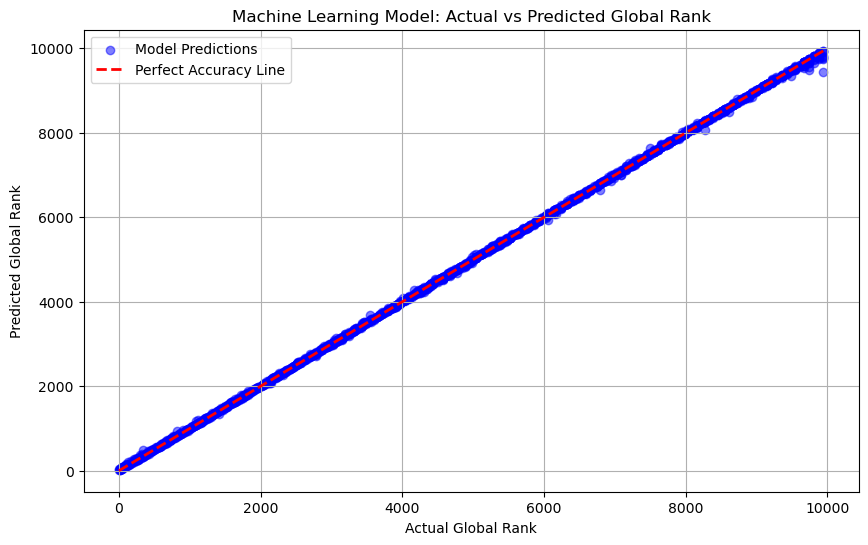


--------------------------------------------------



C:\Users\ASUS\AppData\Local\Temp\ipykernel_5628\4145096115.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importance_scores, y=X.columns, palette='viridis')


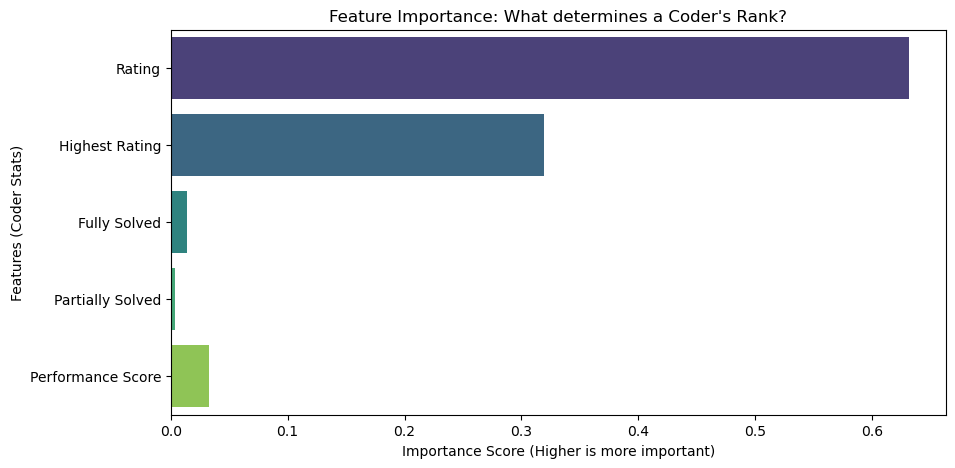

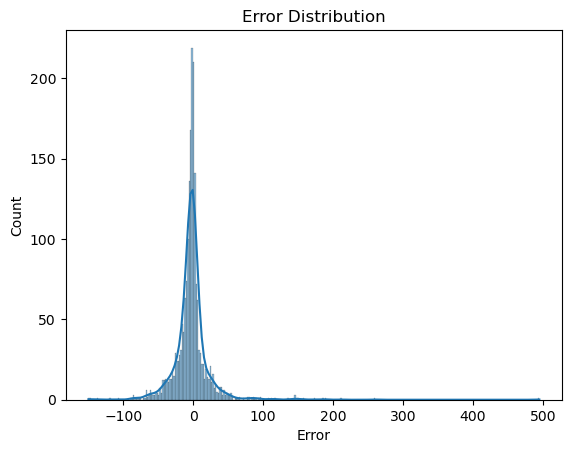

In [10]:
# IMPORT LIBRARIES FOR MAKING GRAPHS
import matplotlib.pyplot as plt
import seaborn as sns

# --- STEP 4: VISUALIZATION (GRAPHS FOR PROJECT FILE) ---

# Graph 1: Actual Rank vs Predicted Rank
plt.figure(figsize=(10, 6))
# Plotting the points
plt.scatter(y_test, predictions, alpha=0.5, color='blue', label='Model Predictions')
# Plotting the perfect prediction line (Red dashed line)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Accuracy Line')

plt.title('Machine Learning Model: Actual vs Predicted Global Rank')
plt.xlabel('Actual Global Rank')
plt.ylabel('Predicted Global Rank')
plt.legend()
plt.grid(True)
plt.show()

print("\n--------------------------------------------------\n")

# Graph 2: Feature Importance (Which stat matters the most?)
plt.figure(figsize=(10, 5))
# Getting the importance scores from our trained model
importance_scores = model.feature_importances_

# Creating a bar chart
sns.barplot(x=importance_scores, y=X.columns, palette='viridis')
plt.title('Feature Importance: What determines a Coder\'s Rank?')
plt.xlabel('Importance Score (Higher is more important)')
plt.ylabel('Features (Coder Stats)')
plt.show()

sns.histplot(y_test - predictions, kde=True)
plt.title("Error Distribution")
plt.xlabel("Error")
plt.show()

In [11]:
import pandas as pd

# --- STEP 5: PREDICTING RANK FOR A NEW USER ---

# 1. Enter the statistics of the new coder here
# (You can change these numbers to test different scenarios)
new_user_data = {
    'Rating': [1500],           # The user's current CodeChef rating
    'Highest Rating': [1650],   # Their highest ever rating
    'Fully Solved': [120],      # Number of questions completely solved
    'Partially Solved': [5]     # Number of questions partially solved
}

# 2. Convert the dictionary into a pandas DataFrame (Machine expects this format)
new_user_df = pd.DataFrame(new_user_data)

# Add Performance Score
new_user_df['Performance Score'] = new_user_df['Rating'] / new_user_df['Highest Rating']

# 3. Ask the trained Random Forest model to predict the rank
predicted_rank = model.predict(new_user_df)

# 4. Display the final predicted rank (converted to an integer/whole number)
print("--------------------------------------------------")
print(f"The Predicted Global Rank for this coder is: {int(predicted_rank[0])}")
print("--------------------------------------------------")

--------------------------------------------------
The Predicted Global Rank for this coder is: 9899
--------------------------------------------------


In [12]:
import pickle

# Hum apne train kiye hue 'model' ko ek file mein save kar rahe hain
with open('rank_predictor_model.pkl', 'wb') as file:
    pickle.dump(model, file)

print("Model successfully saved as 'rank_predictor_model.pkl'!")

Model successfully saved as 'rank_predictor_model.pkl'!


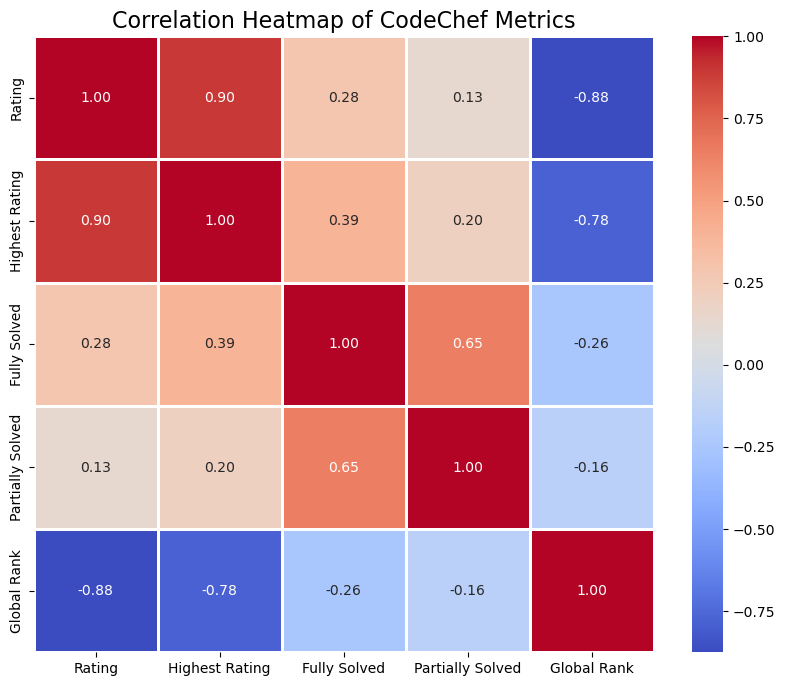

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Aapki asli file 'codechef_data.csv' yahan load ho rahi hai
df = pd.read_csv('codechef_data.csv') 

# 2. Aapke dataset ke exact column names yahan daal diye hain
columns_for_heatmap = ['Rating', 'Highest Rating', 'Fully Solved', 'Partially Solved', 'Global Rank']

# 3. Sirf in columns ka data alag nikalein
data_for_heatmap = df[columns_for_heatmap]

# 4. Correlation calculate karein
corr_matrix = data_for_heatmap.corr()

# 5. Graph ka size aur style set karein
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=1)

# 6. Title lagayein aur graph show karein
plt.title('Correlation Heatmap of CodeChef Metrics', fontsize=16)
plt.show()